In [1]:
import pandas as pd
import numpy as np

cfq_2011 = pd.read_sas("CFQ_G.xpt")
cfq_2013 = pd.read_sas("CFQ_H.xpt")

print("2011–2012 shape:", cfq_2011.shape)
print("2013–2014 shape:", cfq_2013.shape)

print("\nColumns:")
print(cfq_2011.columns.tolist())

print("\nFirst rows:")
display(cfq_2011.head())

2011–2012 shape: (1687, 19)
2013–2014 shape: (1785, 19)

Columns:
['SEQN', 'CFASTAT', 'CFALANG', 'CFDCCS', 'CFDCRNC', 'CFDCST1', 'CFDCST2', 'CFDCST3', 'CFDCSR', 'CFDCIT1', 'CFDCIT2', 'CFDCIT3', 'CFDCIR', 'CFDAPP', 'CFDARNC', 'CFDAST', 'CFDDPP', 'CFDDRNC', 'CFDDS']

First rows:


,SEQN,CFASTAT,CFALANG,CFDCCS,CFDCRNC,CFDCST1,CFDCST2,CFDCST3,CFDCSR,CFDCIT1,CFDCIT2,CFDCIT3,CFDCIR,CFDAPP,CFDARNC,CFDAST,CFDDPP,CFDDRNC,CFDDS
0,62174.0,1.0,1.0,1.0,NaN,3.0,6.0,7.0,5.0,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,1.0,NaN,18.0,1.0,NaN,33.0
1,62178.0,1.0,1.0,1.0,NaN,3.0,5.0,5.0,3.0,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,1.0,NaN,12.0,1.0,NaN,38.0
2,62191.0,1.0,1.0,1.0,NaN,4.0,5.0,7.0,5.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.0,NaN,17.0,1.0,NaN,26.0
3,62209.0,1.0,2.0,1.0,NaN,3.0,3.0,5.0,3.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.0,NaN,15.0,2.0,NaN,NaN
4,62215.0,1.0,1.0,1.0,NaN,5.0,8.0,8.0,7.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.0,NaN,15.0,1.0,NaN,47.0


In [2]:
cfq_2011["cycle"] = "2011-2012"
cfq_2013["cycle"] = "2013-2014"

cfq = pd.concat(
    [cfq_2011, cfq_2013],
    ignore_index=True
)

print("Combined shape:", cfq.shape)
print("Unique participants:", cfq["SEQN"].nunique())
print("\nDigit-symbol score by cycle:")
print(cfq.groupby("cycle")["CFDDS"].agg(["count", "mean", "std"]))

Combined shape: (3472, 20)
Unique participants: 3472

Digit-symbol score by cycle:
           count       mean        std
cycle                                 
2011-2012   1422  44.912799  17.658565
2013-2014   1592  45.951005  17.231667


In [3]:
demo_2011 = pd.read_sas("DEMO_G.xpt")
demo_2013 = pd.read_sas("DEMO_H.xpt")

demo_2011["cycle"] = "2011-2012"
demo_2013["cycle"] = "2013-2014"

demo = pd.concat(
    [demo_2011, demo_2013],
    ignore_index=True
)

print("Demographics shape:", demo.shape)
print(demo.columns.tolist())

Demographics shape: (19931, 49)
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGY', 'RIDEXAGM', 'DMQMILIZ', 'DMQADFC', 'DMDBORN4', 'DMDCITZN', 'DMDYRSUS', 'DMDEDUC3', 'DMDEDUC2', 'DMDMARTL', 'RIDEXPRG', 'SIALANG', 'SIAPROXY', 'SIAINTRP', 'FIALANG', 'FIAPROXY', 'FIAINTRP', 'MIALANG', 'MIAPROXY', 'MIAINTRP', 'AIALANGA', 'WTINT2YR', 'WTMEC2YR', 'SDMVPSU', 'SDMVSTRA', 'INDHHIN2', 'INDFMIN2', 'INDFMPIR', 'DMDHHSIZ', 'DMDFMSIZ', 'DMDHHSZA', 'DMDHHSZB', 'DMDHHSZE', 'DMDHRGND', 'DMDHRAGE', 'DMDHRBR4', 'DMDHREDU', 'DMDHRMAR', 'DMDHSEDU', 'cycle']


In [4]:
# Select demographic and survey-design variables
demo_selected = demo[
    [
        "SEQN",
        "RIDAGEYR",
        "RIAGENDR",
        "DMDEDUC2",
        "WTMEC2YR",
        "SDMVPSU",
        "SDMVSTRA",
        "cycle"
    ]
].copy()

# Merge with cognitive data
df = cfq.merge(
    demo_selected,
    on=["SEQN", "cycle"],
    how="left",
    validate="one_to_one"
)

print("Merged shape:", df.shape)
print("\nMissing values:")
print(
    df[
        [
            "RIDAGEYR",
            "RIAGENDR",
            "DMDEDUC2",
            "CFDDS"
        ]
    ].isna().sum()
)

print("\nAge range:")
print(df["RIDAGEYR"].min(), "to", df["RIDAGEYR"].max())

Merged shape: (3472, 26)

Missing values:
RIDAGEYR      0
RIAGENDR      0
DMDEDUC2      0
CFDDS       458
dtype: int64

Age range:
60.0 to 80.0


In [5]:
# Keep participants with a valid digit-symbol score
analysis = df.dropna(subset=["CFDDS"]).copy()

# Convert special education response codes to missing
analysis["DMDEDUC2"] = analysis["DMDEDUC2"].replace(
    {7: np.nan, 9: np.nan}
)

# Add readable labels
analysis["sex"] = analysis["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

education_labels = {
    1: "Less than 9th grade",
    2: "9th–11th grade",
    3: "High school graduate/GED",
    4: "Some college/AA degree",
    5: "College graduate or above"
}

analysis["education"] = analysis["DMDEDUC2"].map(education_labels)

print("Participants with digit-symbol scores:", len(analysis))
print("\nEducation categories:")
print(analysis["education"].value_counts(dropna=False))

print("\nSex categories:")
print(analysis["sex"].value_counts(dropna=False))

print("\nCognitive score summary:")
print(analysis["CFDDS"].describe().round(2))

Participants with digit-symbol scores: 3014

Education categories:
education
Some college/AA degree       843
High school graduate/GED     702
College graduate or above    692
9th–11th grade               427
Less than 9th grade          347
NaN                            3
Name: count, dtype: int64

Sex categories:
sex
Female    1545
Male      1469
Name: count, dtype: int64

Cognitive score summary:
count    3014.00
mean       45.46
std        17.44
min         0.00
25%        33.00
50%        45.00
75%        58.00
max       105.00
Name: CFDDS, dtype: float64


In [6]:
# Group ages into 5-year bands
analysis["age_group"] = pd.cut(
    analysis["RIDAGEYR"],
    bins=[59, 64, 69, 74, 79, 80],
    labels=["60–64", "65–69", "70–74", "75–79", "80"]
)

age_summary = (
    analysis.groupby("age_group", observed=False)["CFDDS"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(age_summary)

,count,mean,median,std
age_group,,,,
60–64,945,51.29,52.0,17.63
65–69,683,46.35,46.0,17.41
70–74,567,44.83,46.0,16.35
75–79,327,39.57,41.0,16.01
80,492,37.67,38.0,14.78


In [7]:
education_summary = (
    analysis.groupby("education", observed=True)["CFDDS"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
    .round(2)
)

display(education_summary)

,count,mean,median,std
education,,,,
College graduate or above,692,55.61,56.0,15.43
Some college/AA degree,843,50.68,51.0,15.19
High school graduate/GED,702,44.51,44.0,14.84
9th–11th grade,427,36.65,36.0,13.83
Less than 9th grade,347,25.39,24.0,12.37


In [8]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    analysis["RIDAGEYR"],
    analysis["CFDDS"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4g}")
print(f"Participants: {len(analysis)}")

Spearman correlation: -0.280
P-value: 1.341e-55
Participants: 3014


In [9]:
import statsmodels.formula.api as smf

model_data = analysis.dropna(
    subset=["CFDDS", "RIDAGEYR", "sex", "education"]
).copy()

model = smf.ols(
    "CFDDS ~ RIDAGEYR + C(sex) + C(education)",
    data=model_data
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  CFDDS   R-squared:                       0.386
Model:                            OLS   Adj. R-squared:                  0.385
Method:                 Least Squares   F-statistic:                     315.2
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          4.61e-314
Time:                        11:36:52   Log-Likelihood:                -12144.
No. Observations:                3011   AIC:                         2.430e+04
Df Residuals:                    3004   BIC:                         2.434e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [10]:
print("Cycle counts:")
print(analysis["cycle"].value_counts())

print("\nExamination weights:")
print(analysis["WTMEC2YR"].describe())

print("\nMissing or invalid design values:")
print(
    analysis[["WTMEC2YR", "SDMVSTRA", "SDMVPSU"]]
    .isna()
    .sum()
)

print("\nNon-positive examination weights:",
      (analysis["WTMEC2YR"] <= 0).sum())

Cycle counts:
cycle
2013-2014    1592
2011-2012    1422
Name: count, dtype: int64

Examination weights:
count      3014.000000
mean      35987.397982
std       34465.858641
min        4413.314520
25%       12378.189325
50%       18941.404467
75%       50157.496518
max      175827.980982
Name: WTMEC2YR, dtype: float64

Missing or invalid design values:
WTMEC2YR    0
SDMVSTRA    0
SDMVPSU     0
dtype: int64

Non-positive examination weights: 0


In [11]:
# Create combined four-year examination weights
analysis["WTMEC4YR"] = analysis["WTMEC2YR"] / 2

print(
    analysis[
        ["WTMEC2YR", "WTMEC4YR"]
    ].describe().round(2)
)

print("\nSurvey strata:", analysis["SDMVSTRA"].nunique())
print("Unique PSU-stratum combinations:",
      analysis[["SDMVSTRA", "SDMVPSU"]].drop_duplicates().shape[0])

        WTMEC2YR  WTMEC4YR
count    3014.00   3014.00
mean    35987.40  17993.70
std     34465.86  17232.93
min      4413.31   2206.66
25%     12378.19   6189.09
50%     18941.40   9470.70
75%     50157.50  25078.75
max    175827.98  87913.99

Survey strata: 29
Unique PSU-stratum combinations: 61


In [12]:
# Check strata and PSU identifiers within each cycle
print(
    analysis.groupby("cycle").agg(
        participants=("SEQN", "size"),
        strata=("SDMVSTRA", "nunique"),
        psus=("SDMVPSU", "nunique")
    )
)

print("\nStrata appearing in both cycles:")
strata_by_cycle = analysis.groupby("cycle")["SDMVSTRA"].unique()

shared_strata = set(strata_by_cycle.iloc[0]) & set(strata_by_cycle.iloc[1])
print(sorted(shared_strata))

           participants  strata  psus
cycle                                
2011-2012          1422      14     3
2013-2014          1592      15     2

Strata appearing in both cycles:
[]


In [13]:
print(analysis.groupby("cycle")["SDMVPSU"].value_counts().sort_index())
print("\nUnique PSU codes:", sorted(analysis["SDMVPSU"].unique()))

cycle      SDMVPSU
2011-2012  1.0        678
           2.0        645
           3.0         99
2013-2014  1.0        805
           2.0        787
Name: count, dtype: int64

Unique PSU codes: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]


In [14]:
%pip install svy

Note: you may need to restart the kernel to use updated packages.


In [15]:
import svy
print("svy imported successfully")

svy imported successfully


In [16]:
import polars as pl
import svy

analysis_pl = pl.from_pandas(analysis)

design = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC4YR"
)

sample = svy.Sample(
    data=analysis_pl,
    design=design
)

print(sample)

╭─────────── Sample ────────────╮
│ Survey Data                   │
│   Rows     : 3014             │
│   Columns  : 30               │
│   Strata   : 29               │
│   PSUs     : 61               │
│                               │
│ Survey Design                 │
│   Case id            None     │
│   Wave               None     │
│   Stratum            SDMVSTRA │
│   PSU                SDMVPSU  │
│   SSU                None     │
│   Weight             WTMEC4YR │
│   With replacement   False    │
│   Prob               None     │
│   Hit                None     │
│   MOS                None     │
│   Population size    None     │
│   Replicate weights  None     │
╰───────────────────────────────╯

In [17]:
import inspect

print(inspect.signature(svy.Design))

(case_id: 'str | Sequence[str] | None' = None, wave: 'str | None' = None, stratum: 'str | Sequence[str] | None' = None, wgt: 'str | None' = None, prob: 'str | None' = None, hit: 'str | None' = None, mos: 'str | None' = None, psu: 'str | Sequence[str] | None' = None, ssu: 'str | Sequence[str] | None' = None, pop_size: 'str | PopSize | None' = None, wr: 'bool' = False, rep_wgts: 'RepWgts | None' = None, wgt_adjustment: 'WgtAdjustment | None' = None, singleton: 'Singleton | SingletonMethodName | None' = None, **parts: 'Any') -> 'None'


In [18]:
# Keep participants with complete model variables
model_data = analysis.dropna(
    subset=["CFDDS", "RIDAGEYR", "sex", "education",
            "WTMEC4YR", "SDMVSTRA", "SDMVPSU"]
).copy()

model_pl = pl.from_pandas(model_data)

# Define the NHANES survey design
design = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC4YR",
    wr=True
)

sample_model = svy.Sample(
    data=model_pl,
    design=design
)

# Survey-adjusted linear regression
model_svy = sample_model.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade")
    ],
    family="gaussian"
)

print(model_svy)

╭──────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                           │
│                                                                                                           │
│ Observations         3011  AIC           24164.2422                                                       │
│ DF Residuals           26  BIC                    -                                                       │
│ Deviance      535306.0621  Scale           178.1978                                                       │
│ R-squared         0.38057  R-sq (adj)       0.37934                                                       │
│                            Iterations             2                                                       │
│ F-stat (adj)    110.52964  Prob (F-adj)      <0.001                                                       │
│                                                                                                           │
│                                                                                                           │
│  Term                                      Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                           105.90110    3.28501    32.23772   <0.001    99.14867   112.65352  │
│  RIDAGEYR                               -0.90110    0.04472   -20.15117   <0.001    -0.99302    -0.80918  │
│  sex_Male                               -4.73639    0.51956    -9.11608   <0.001    -5.80437    -3.66841  │
│  education_College graduate or above    17.83146    1.14140    15.62250   <0.001    15.48529    20.17764  │
│  education_High school graduate/GED      7.34702    0.85783     8.56462   <0.001     5.58372     9.11032  │
│  education_Less than 9th grade         -11.58622    1.33821    -8.65799   <0.001   -14.33695    -8.83548  │
│  education_Some college/AA degree       13.09613    0.99156    13.20754   <0.001    11.05794    15.13432  │
│                                                                                                           │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

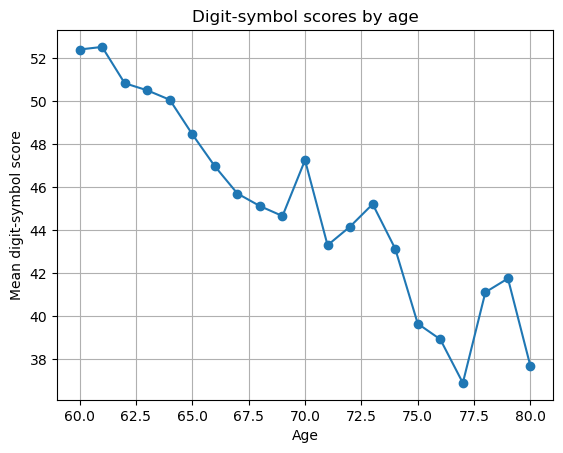

In [19]:
import matplotlib.pyplot as plt

age_means = (
    analysis.groupby("RIDAGEYR")["CFDDS"]
    .mean()
)

age_means.plot(kind="line", marker="o")
plt.xlabel("Age")
plt.ylabel("Mean digit-symbol score")
plt.title("Digit-symbol scores by age")
plt.grid(True)
plt.show()

In [20]:
analysis["age_squared"] = analysis["RIDAGEYR"] ** 2

design = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC4YR",
    wr=True
)

sample_model = svy.Sample(
    data=pl.from_pandas(
        analysis.dropna(
            subset=[
                "CFDDS", "RIDAGEYR", "age_squared",
                "sex", "education", "WTMEC4YR",
                "SDMVSTRA", "SDMVPSU"
            ]
        )
    ),
    design=design
)

model_nonlinear = sample_model.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        "age_squared",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade")
    ],
    family="gaussian"
)

print(model_nonlinear)

╭──────────────────────────────────────── GLM: Gaussian (identity) ────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                          │
│                                                                                                          │
│ Observations         3011  AIC           24164.6514                                                      │
│ DF Residuals           25  BIC                    -                                                      │
│ Deviance      534954.2995  Scale           178.1400                                                      │
│ R-squared         0.38098  R-sq (adj)       0.37954                                                      │
│                            Iterations             2                                                      │
│ F-stat (adj)     90.63623  Prob (F-adj)      <0.001                                                      │
│                                                                                                          │
│                                                                                                          │
│  Term                                      Coef.   Std.Err.          t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                            59.95926   35.75919    1.67675   0.1061   -13.68817   133.60668  │
│  RIDAGEYR                                0.41575    1.02694    0.40485   0.6890    -1.69927     2.53078  │
│  age_squared                            -0.00936    0.00731   -1.28030   0.2122    -0.02441     0.00569  │
│  sex_Male                               -4.74837    0.51857   -9.15661   <0.001    -5.81639    -3.68035  │
│  education_College graduate or above    17.87738    1.14266   15.64544   <0.001    15.52403    20.23072  │
│  education_High school graduate/GED      7.39790    0.86285    8.57380   <0.001     5.62083     9.17497  │
│  education_Less than 9th grade         -11.53590    1.34415   -8.58228   <0.001   -14.30423    -8.76756  │
│  education_Some college/AA degree       13.12456    0.98280   13.35422   <0.001    11.10044    15.14868  │
│                                                                                                          │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [21]:
# Model A: age only
model_age = sample_model.glm.fit(
    y="CFDDS",
    x=["RIDAGEYR"],
    family="gaussian"
)

# Model B: age + sex
model_age_sex = sample_model.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female")
    ],
    family="gaussian"
)

print("MODEL A: Age only")
print(model_age)

print("\nMODEL B: Age + sex")
print(model_age_sex)

MODEL A: Age only


╭──────────────────────────── GLM: Gaussian (identity) ─────────────────────────────╮
│ Modeling: CFDDS                                                                   │
│                                                                                   │
│ Observations         3011  AIC           25070.5392                               │
│ DF Residuals           31  BIC                    -                               │
│ Deviance      727222.3871  Scale           241.6824                               │
│ R-squared         0.15850  R-sq (adj)       0.15822                               │
│                            Iterations             2                               │
│ F-stat (adj)    455.36355  Prob (F-adj)      <0.001                               │
│                                                                                   │
│                                                                                   │
│  Term              Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_   121.97347    3.48359    35.01370   <0.001   114.86863   129.07830  │
│  RIDAGEYR       -1.01305    0.04747   -21.33925   <0.001    -1.10988    -0.91623  │
│                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────╯



MODEL B: Age + sex


╭──────────────────────────── GLM: Gaussian (identity) ─────────────────────────────╮
│ Modeling: CFDDS                                                                   │
│                                                                                   │
│ Observations         3011  AIC           25021.0782                               │
│ DF Residuals           30  BIC                    -                               │
│ Deviance      714981.0647  Scale           237.6932                               │
│ R-squared         0.17266  R-sq (adj)       0.17211                               │
│                            Iterations             2                               │
│ F-stat (adj)    342.93035  Prob (F-adj)      <0.001                               │
│                                                                                   │
│                                                                                   │
│  Term              Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_   124.80200    3.27107    38.15324   <0.001   118.12158   131.48242  │
│  RIDAGEYR       -1.02725    0.04532   -22.66859   <0.001    -1.11980    -0.93471  │
│  sex_Male       -4.05331    0.53758    -7.53986   <0.001    -5.15120    -2.95541  │
│                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────╯

In [22]:
model_age_education = sample_model.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("education", ref="9th–11th grade")
    ],
    family="gaussian"
)

print(model_age_education)

╭──────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                           │
│                                                                                                           │
│ Observations         3011  AIC           24254.0057                                                       │
│ DF Residuals           27  BIC                    -                                                       │
│ Deviance      551764.2534  Scale           183.6154                                                       │
│ R-squared         0.36153  R-sq (adj)       0.36047                                                       │
│                            Iterations             2                                                       │
│ F-stat (adj)    121.96681  Prob (F-adj)      <0.001                                                       │
│                                                                                                           │
│                                                                                                           │
│  Term                                      Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                           102.89496    3.63481    28.30822   <0.001    95.43694   110.35297  │
│  RIDAGEYR                               -0.88666    0.04925   -18.00369   <0.001    -0.98772    -0.78561  │
│  education_College graduate or above    17.26435    1.21342    14.22788   <0.001    14.77463    19.75408  │
│  education_High school graduate/GED      7.41505    0.95727     7.74604   <0.001     5.45090     9.37921  │
│  education_Less than 9th grade         -11.92102    1.38750    -8.59175   <0.001   -14.76792    -9.07411  │
│  education_Some college/AA degree       13.18377    1.07064    12.31393   <0.001    10.98700    15.38054  │
│                                                                                                           │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [23]:
model_age_education_interaction = sample_model.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cross(
            "RIDAGEYR",
            svy.Cat("education", ref="9th–11th grade")
        )
    ],
    family="gaussian"
)

print(model_age_education_interaction)

╭──────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                                   │
│                                                                                                                   │
│ Observations         3011  AIC           24143.0274                                                               │
│ DF Residuals           22  BIC                    -                                                               │
│ Deviance      529722.2218  Scale           176.5741                                                               │
│ R-squared         0.38704  R-sq (adj)       0.38499                                                               │
│                            Iterations             2                                                               │
│ F-stat (adj)     72.53747  Prob (F-adj)      <0.001                                                               │
│                                                                                                                   │
│                                                                                                                   │
│  Term                                               Coef.   Std.Err.          t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                     87.90443    9.39915    9.35238   <0.001    68.41179   107.39708  │
│  RIDAGEYR                                        -0.64571    0.13008   -4.96412   <0.001    -0.91547    -0.37595  │
│  sex_Male                                        -4.64031    0.50165   -9.25016   <0.001    -5.68066    -3.59996  │
│  education_College graduate or above             47.91662   11.44430    4.18694   <0.001    24.18260    71.65064  │
│  education_High school graduate/GED              12.49127   11.52662    1.08369   0.2902   -11.41347    36.39602  │
│  education_Less than 9th grade                  -25.51115   14.94844   -1.70661   0.1020   -56.51232     5.49002  │
│  education_Some college/AA degree                40.81519   10.08640    4.04656   <0.001    19.89728    61.73310  │
│  RIDAGEYR:education_College graduate or above    -0.43269    0.15678   -2.75993   0.0114    -0.75783    -0.10756  │
│  RIDAGEYR:education_High school graduate/GED     -0.07164    0.16199   -0.44225   0.6626    -0.40758     0.26430  │
│  RIDAGEYR:education_Less than 9th grade           0.19364    0.20682    0.93626   0.3593    -0.23529     0.62257  │
│  RIDAGEYR:education_Some college/AA degree       -0.39699    0.14181   -2.79943   0.0104    -0.69109    -0.10289  │
│                                                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [24]:
[name for name in dir(model_age_education_interaction)
 if "test" in name.lower() or "wald" in name.lower()]

['term_test']

In [25]:
import inspect

print(inspect.signature(model_age_education_interaction.term_test))
print(model_age_education_interaction.term_test.__doc__)

(term: "'str | Cat'") -> 'FDist'
Joint Wald test on a model term; see GLMFit.term_test.


In [26]:
print(model_age_education_interaction.term_test.__doc__)

Joint Wald test on a model term; see GLMFit.term_test.


In [27]:
help(model_age_education_interaction.term_test)

Help on method term_test in module svy.regression.base:

term_test(term: "'str | Cat'") -> 'FDist' method of svy.regression.base.GLM instance
    Joint Wald test on a model term; see GLMFit.term_test.



In [28]:
model_age_education_interaction.term_test(
    "RIDAGEYR:education_College graduate or above"
)

FDist(df_num=1, df_den=22.0, value=7.6172094753911, p_value=0.011427261914314155)

In [29]:
import inspect
print(inspect.getsource(type(model_age_education_interaction).term_test))

    def term_test(self, term: "str | Cat") -> FDist:
        """Joint Wald test on a model term; see GLMFit.term_test."""
        return self._ensure_fitted().term_test(term)



In [30]:
import inspect
from svy.regression.base import GLMFit

print(inspect.signature(GLMFit.term_test))
print(inspect.getsource(GLMFit.term_test))

(self, term: "'str | Cat'") -> 'FDist'
    def term_test(self, term: "str | Cat") -> FDist:
        """Joint Wald test that every coefficient of a model term is zero.

        ``term`` is a feature as passed to ``fit`` — a continuous column
        name, a categorical (by name or ``Cat``), or one exact coefficient
        name. For a categorical this jointly tests all its non-reference
        dummies: ``F = β̂ᵀ V⁻¹ β̂ / q`` on ``(q, design df)``, the
        counterpart of R's ``regTermTest(method="Wald")`` (the working
        likelihood-ratio variant is not implemented).
        """
        from scipy import stats as sp_stats

        name = getattr(term, "name", term)
        if not isinstance(name, str):
            raise TypeError(f"term must be a str or Cat, got {type(term).__name__}")

        info = (self.term_info or {}).get(name)
        if info is not None and info.get("type") == "categorical":
            cols = [f"{name}_{lvl}" for lvl in info["levels"][1:]]
        else:

In [31]:
fit = model_age_education_interaction._ensure_fitted()

print("Coefficient names:")
print(fit.keys())

print("\nCovariance matrix shape:")
print(fit.cov_matrix.shape)

Coefficient names:
['_intercept_', 'RIDAGEYR', 'sex_Male', 'education_College graduate or above', 'education_High school graduate/GED', 'education_Less than 9th grade', 'education_Some college/AA degree', 'RIDAGEYR:education_College graduate or above', 'RIDAGEYR:education_High school graduate/GED', 'RIDAGEYR:education_Less than 9th grade', 'RIDAGEYR:education_Some college/AA degree']

Covariance matrix shape:
(11, 11)


In [32]:
import numpy as np
from scipy import stats

fit = model_age_education_interaction._ensure_fitted()

# Identify the four age-by-education interaction coefficients
interaction_names = [
    name for name in fit.keys()
    if name.startswith("RIDAGEYR:education_")
]

# Get their coefficient estimates and covariance matrix
names = fit.keys()
idx = [names.index(name) for name in interaction_names]

beta = np.array([fit.coefs[i].est for i in idx])
cov = fit.cov_matrix[np.ix_(idx, idx)]

# Joint Wald F-test
q = len(idx)
f_stat = float(beta @ np.linalg.solve(cov, beta) / q)
df_den = fit._design_df()
p_value = stats.f.sf(f_stat, q, df_den)

print("Interaction coefficients tested:", q)
print(f"F-statistic: {f_stat:.3f}")
print(f"Degrees of freedom: ({q}, {df_den})")
print(f"p-value: {p_value:.6g}")

Interaction coefficients tested: 4
F-statistic: 9.114
Degrees of freedom: (4, 22.0)
p-value: 0.000168619


In [33]:
import pandas as pd

mcq_g = pd.read_sas("MCQ_G.XPT")
mcq_h = pd.read_sas("MCQ_H.XPT")

print("2011–2012:", mcq_g.shape)
print("2013–2014:", mcq_h.shape)

2011–2012: (9364, 92)
2013–2014: (9770, 95)


In [34]:
mcq = pd.concat([mcq_g, mcq_h], ignore_index=True)

print("Combined shape:", mcq.shape)
print("Unique participants:", mcq["SEQN"].nunique())
print("Duplicate IDs:", mcq["SEQN"].duplicated().sum())
print("Stroke variable exists:", "MCQ160F" in mcq.columns)

Combined shape: (19134, 97)
Unique participants: 19134
Duplicate IDs: 0
Stroke variable exists: True


In [35]:
print(mcq["MCQ160F"].value_counts(dropna=False).sort_index())

MCQ160F
1.0      431
2.0    10888
7.0        1
9.0        8
NaN     7806
Name: count, dtype: int64


In [36]:
# Keep only the required columns
mcq_stroke = mcq[["SEQN", "MCQ160F"]].copy()

# Recode responses
mcq_stroke["stroke_history"] = mcq_stroke["MCQ160F"].map({
    1.0: "Yes",
    2.0: "No"
})

# Keep only ID and the new variable
mcq_stroke = mcq_stroke[["SEQN", "stroke_history"]]

# Merge with the existing cognitive dataset
analysis = analysis.merge(
    mcq_stroke,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

print("Shape:", analysis.shape)
print(analysis["stroke_history"].value_counts(dropna=False))

Shape: (3014, 32)
stroke_history
No     2797
Yes     212
NaN       5
Name: count, dtype: int64


In [37]:
analysis.groupby("stroke_history")["CFDDS"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
stroke_history,,,,
No,2797,46.17,46.0,17.29
Yes,212,35.96,35.0,16.76


In [38]:
model_data_stroke = analysis.dropna(
    subset=[
        "CFDDS", "RIDAGEYR", "sex", "education",
        "stroke_history", "WTMEC4YR", "SDMVSTRA", "SDMVPSU"
    ]
).copy()

model_pl_stroke = pl.from_pandas(model_data_stroke)

design_stroke = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC4YR",
    wr=True
)

sample_stroke = svy.Sample(
    data=model_pl_stroke,
    design=design_stroke
)

model_stroke = sample_stroke.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cat("stroke_history", ref="No")
    ],
    family="gaussian"
)

print(model_stroke)

╭──────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                           │
│                                                                                                           │
│ Observations         3006  AIC           24084.7357                                                       │
│ DF Residuals           25  BIC                    -                                                       │
│ Deviance      526987.7900  Scale           175.7798                                                       │
│ R-squared         0.38978  R-sq (adj)       0.38835                                                       │
│                            Iterations             2                                                       │
│ F-stat (adj)     95.23560  Prob (F-adj)      <0.001                                                       │
│                                                                                                           │
│                                                                                                           │
│  Term                                      Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                           104.88959    3.42414    30.63235   <0.001    97.83743   111.94174  │
│  RIDAGEYR                               -0.87842    0.04559   -19.26700   <0.001    -0.97231    -0.78452  │
│  sex_Male                               -4.74152    0.49234    -9.63056   <0.001    -5.75551    -3.72752  │
│  education_College graduate or above    17.56535    1.11495    15.75441   <0.001    15.26907    19.86163  │
│  education_High school graduate/GED      7.36058    0.86652     8.49444   <0.001     5.57596     9.14521  │
│  education_Less than 9th grade         -11.60804    1.39151    -8.34204   <0.001   -14.47391    -8.74217  │
│  education_Some college/AA degree       12.95896    0.98241    13.19096   <0.001    10.93565    14.98228  │
│  stroke_history_Yes                     -6.60078    1.16262    -5.67749   <0.001    -8.99524    -4.20631  │
│                                                                                                           │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [39]:
print("PSU codes by survey cycle:")
print(
    analysis.groupby("cycle")["SDMVPSU"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nNumber of distinct PSUs per stratum:")
print(
    analysis.groupby(["cycle", "SDMVSTRA"])["SDMVPSU"]
    .nunique()
    .value_counts()
    .sort_index()
)

PSU codes by survey cycle:
cycle      SDMVPSU
2011-2012  1.0        678
           2.0        645
           3.0         99
2013-2014  1.0        805
           2.0        787
Name: count, dtype: int64

Number of distinct PSUs per stratum:
SDMVPSU
2    26
3     3
Name: count, dtype: int64


In [40]:
print("DEMO_G — 2011–2012")
print(demo_2011["SDMVPSU"].value_counts(dropna=False).sort_index())

print("\nDEMO_H — 2013–2014")
print(demo_2013["SDMVPSU"].value_counts(dropna=False).sort_index())

DEMO_G — 2011–2012
SDMVPSU
1.0    4374
2.0    4490
3.0     892
Name: count, dtype: int64

DEMO_H — 2013–2014
SDMVPSU
1.0    5249
2.0    4926
Name: count, dtype: int64


In [41]:
print(
    analysis.groupby(["cycle", "SDMVSTRA"])["SDMVPSU"]
    .nunique()
    .sort_index()
)

cycle      SDMVSTRA
2011-2012  90.0        3
           91.0        3
           92.0        3
           93.0        2
           94.0        2
           95.0        2
           96.0        2
           97.0        2
           98.0        2
           99.0        2
           100.0       2
           101.0       2
           102.0       2
           103.0       2
2013-2014  104.0       2
           105.0       2
           106.0       2
           107.0       2
           108.0       2
           109.0       2
           110.0       2
           111.0       2
           112.0       2
           113.0       2
           114.0       2
           115.0       2
           116.0       2
           117.0       2
           118.0       2
Name: SDMVPSU, dtype: int64


In [42]:
print(sample_stroke)

╭─────────── Sample ────────────╮
│ Survey Data                   │
│   Rows     : 3006             │
│   Columns  : 32               │
│   Strata   : 29               │
│   PSUs     : 61               │
│                               │
│ Survey Design                 │
│   Case id            None     │
│   Wave               None     │
│   Stratum            SDMVSTRA │
│   PSU                SDMVPSU  │
│   SSU                None     │
│   Weight             WTMEC4YR │
│   With replacement   True     │
│   Prob               None     │
│   Hit                None     │
│   MOS                None     │
│   Population size    None     │
│   Replicate weights  None     │
╰───────────────────────────────╯

In [43]:
dpq_g = pd.read_sas("DPQ_G.XPT")
dpq_h = pd.read_sas("DPQ_H.XPT")

print("2011–2012:", dpq_g.shape)
print("2013–2014:", dpq_h.shape)

2011–2012: (5615, 11)
2013–2014: (5924, 11)


In [44]:
print(dpq_g.columns.tolist())
print(dpq_h.columns.tolist())

['SEQN', 'DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090', 'DPQ100']
['SEQN', 'DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090', 'DPQ100']


In [45]:
dpq = pd.concat([dpq_g, dpq_h], ignore_index=True)

print("Combined shape:", dpq.shape)
print("Unique participants:", dpq["SEQN"].nunique())

print(dpq[
    ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050",
     "DPQ060", "DPQ070", "DPQ080", "DPQ090"]
].apply(pd.Series.value_counts).sort_index())

Combined shape: (11539, 11)
Unique participants: 11539
              DPQ010  DPQ020  DPQ030  DPQ040  DPQ050  DPQ060  DPQ070  DPQ080  \
5.397605e-79    7702    7834    6543    5274    7793    8529    8565    9179   
1.000000e+00    1681    1720    2195    3377    1564    1175    1081     698   
2.000000e+00     507     404     669     795     497     303     339     228   
3.000000e+00     443     376     930     892     482     321     348     226   
7.000000e+00       3       4       2       2       1       2       2       2   
9.000000e+00      13       7       4       2       5      10       5       6   

              DPQ090  
5.397605e-79    9952  
1.000000e+00     246  
2.000000e+00      64  
3.000000e+00      68  
7.000000e+00       3  
9.000000e+00       4  


In [46]:
# Select the nine symptom questions
phq9_cols = [f"DPQ{i:03d}" for i in range(10, 100, 10)]

# Replace NHANES missing, refused, and don't-know codes
dpq[phq9_cols] = dpq[phq9_cols].replace(
    [5.397605e-79, 7, 9], np.nan
)

# Calculate the total only when all nine answers are available
dpq["PHQ9_score"] = dpq[phq9_cols].sum(
    axis=1, min_count=9
)

print(dpq["PHQ9_score"].describe())
print("Complete PHQ-9 scores:", dpq["PHQ9_score"].notna().sum())
print("Missing PHQ-9 scores:", dpq["PHQ9_score"].isna().sum())

count    1.029700e+04
mean     3.240750e+00
std      4.407781e+00
min      4.857845e-78
25%      4.857845e-78
50%      2.000000e+00
75%      4.000000e+00
max      2.700000e+01
Name: PHQ9_score, dtype: float64
Complete PHQ-9 scores: 10297
Missing PHQ-9 scores: 1242


In [47]:
# Select the nine symptom questions
phq9_cols = [f"DPQ{i:03d}" for i in range(10, 100, 10)]

# Convert the NHANES special missing marker and codes 7/9 to NaN
for col in phq9_cols:
    dpq[col] = dpq[col].mask(
        (dpq[col] < 1e-10) | dpq[col].isin([7, 9])
    )

# Calculate total only when all nine responses are available
dpq["PHQ9_score"] = dpq[phq9_cols].sum(axis=1, min_count=9)

print(dpq["PHQ9_score"].describe())
print("Complete scores:", dpq["PHQ9_score"].notna().sum())
print("Missing scores:", dpq["PHQ9_score"].isna().sum())

count    90.000000
mean     19.477778
std       4.871905
min       9.000000
25%      16.000000
50%      19.000000
75%      24.000000
max      27.000000
Name: PHQ9_score, dtype: float64
Complete scores: 90
Missing scores: 11449


In [48]:
dpq = pd.concat([dpq_g, dpq_h], ignore_index=True)

phq9_cols = [f"DPQ{i:03d}" for i in range(10, 100, 10)]

# Replace the special NHANES marker and refused/don't-know codes
for col in phq9_cols:
    dpq[col] = dpq[col].replace(5.397605e-79, np.nan)
    dpq[col] = dpq[col].replace([7, 9], np.nan)

# Score only participants with all nine valid answers
dpq["PHQ9_score"] = dpq[phq9_cols].sum(axis=1, min_count=9)

print(dpq["PHQ9_score"].describe())
print("Complete scores:", dpq["PHQ9_score"].notna().sum())
print("Missing scores:", dpq["PHQ9_score"].isna().sum())

count    1.029700e+04
mean     3.240750e+00
std      4.407781e+00
min      4.857845e-78
25%      4.857845e-78
50%      2.000000e+00
75%      4.000000e+00
max      2.700000e+01
Name: PHQ9_score, dtype: float64
Complete scores: 10297
Missing scores: 1242


In [49]:
# Start again from the original combined files
dpq = pd.concat([dpq_g, dpq_h], ignore_index=True)

phq9_cols = [f"DPQ{i:03d}" for i in range(10, 100, 10)]

for col in phq9_cols:
    # Valid answers are 0, 1, 2, 3; anything else is missing/invalid
    dpq[col] = dpq[col].where(dpq[col].isin([0, 1, 2, 3]))

dpq["PHQ9_score"] = dpq[phq9_cols].sum(axis=1, min_count=9)

print(dpq["PHQ9_score"].describe())
print("Complete scores:", dpq["PHQ9_score"].notna().sum())
print("Missing scores:", dpq["PHQ9_score"].isna().sum())

count    90.000000
mean     19.477778
std       4.871905
min       9.000000
25%      16.000000
50%      19.000000
75%      24.000000
max      27.000000
Name: PHQ9_score, dtype: float64
Complete scores: 90
Missing scores: 11449


In [50]:
dpq = pd.concat([dpq_g, dpq_h], ignore_index=True)

print(dpq_g["DPQ010"].value_counts(dropna=False).sort_index())
print(dpq_h["DPQ010"].value_counts(dropna=False).sort_index())

DPQ010
5.397605e-79    3726
1.000000e+00     800
2.000000e+00     214
3.000000e+00     201
7.000000e+00       2
9.000000e+00       8
NaN              664
Name: count, dtype: int64
DPQ010
5.397605e-79    3976
1.000000e+00     881
2.000000e+00     293
3.000000e+00     242
7.000000e+00       1
9.000000e+00       5
NaN              526
Name: count, dtype: int64


In [51]:
dpq = pd.concat([dpq_g, dpq_h], ignore_index=True)

phq9_cols = [f"DPQ{i:03d}" for i in range(10, 100, 10)]

for col in phq9_cols:
    # Convert the SAS representation of 0 into a real zero
    dpq[col] = dpq[col].mask(dpq[col] < 1e-10, 0)

    # Refused and don't-know responses are missing
    dpq[col] = dpq[col].replace([7, 9], np.nan)

# Require all nine answers to calculate a total
dpq["PHQ9_score"] = dpq[phq9_cols].sum(axis=1, min_count=9)

print(dpq["PHQ9_score"].describe())
print("Complete scores:", dpq["PHQ9_score"].notna().sum())
print("Missing scores:", dpq["PHQ9_score"].isna().sum())

count    10297.000000
mean         3.240750
std          4.407781
min          0.000000
25%          0.000000
50%          2.000000
75%          4.000000
max         27.000000
Name: PHQ9_score, dtype: float64
Complete scores: 10297
Missing scores: 1242


In [52]:
# Keep only participant ID and calculated score
dpq_scores = dpq[["SEQN", "PHQ9_score"]].copy()

# Merge into the cognitive analysis dataset
analysis = analysis.merge(
    dpq_scores,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

print("Updated shape:", analysis.shape)
print("PHQ-9 scores available:", analysis["PHQ9_score"].notna().sum())
print("PHQ-9 scores missing:", analysis["PHQ9_score"].isna().sum())

Updated shape: (3014, 33)
PHQ-9 scores available: 2944
PHQ-9 scores missing: 70


In [53]:
model_data_phq9 = analysis.dropna(
    subset=[
        "CFDDS", "RIDAGEYR", "sex", "education",
        "stroke_history", "PHQ9_score",
        "WTMEC4YR", "SDMVSTRA", "SDMVPSU"
    ]
).copy()

print("Model sample size:", len(model_data_phq9))
print("Excluded due to missing data:", len(analysis) - len(model_data_phq9))

Model sample size: 2936
Excluded due to missing data: 78


In [54]:
model_pl_phq9 = pl.from_pandas(model_data_phq9)

design_phq9 = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC4YR",
    wr=True
)

sample_phq9 = svy.Sample(
    data=model_pl_phq9,
    design=design_phq9
)

model_phq9 = sample_phq9.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cat("stroke_history", ref="No"),
        "PHQ9_score"
    ],
    family="gaussian"
)

print(model_phq9)

╭──────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                           │
│                                                                                                           │
│ Observations         2936  AIC           23422.7423                                                       │
│ DF Residuals           24  BIC                    -                                                       │
│ Deviance      496734.4383  Scale           169.7077                                                       │
│ R-squared         0.40579  R-sq (adj)       0.40417                                                       │
│                            Iterations             2                                                       │
│ F-stat (adj)     92.52234  Prob (F-adj)      <0.001                                                       │
│                                                                                                           │
│                                                                                                           │
│  Term                                      Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                           109.35799    3.46223    31.58602   <0.001   102.21230   116.50367  │
│  RIDAGEYR                               -0.90368    0.04497   -20.09420   <0.001    -0.99650    -0.81086  │
│  sex_Male                               -5.29250    0.47143   -11.22637   <0.001    -6.26549    -4.31951  │
│  education_College graduate or above    16.46195    1.10563    14.88916   <0.001    14.18004    18.74387  │
│  education_High school graduate/GED      6.64003    0.78328     8.47722   <0.001     5.02342     8.25664  │
│  education_Less than 9th grade         -11.34838    1.36001    -8.34430   <0.001   -14.15531    -8.54145  │
│  education_Some college/AA degree       12.06547    0.87838    13.73608   <0.001    10.25259    13.87835  │
│  stroke_history_Yes                     -5.41908    1.08876    -4.97730   <0.001    -7.66617    -3.17199  │
│  PHQ9_score                             -0.61123    0.09480    -6.44765   <0.001    -0.80688    -0.41557  │
│                                                                                                           │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [55]:
import statsmodels.api as sm

# Fit the ordinary least-squares model for diagnostics
ols_model = sm.OLS(
    model_data_phq9["CFDDS"],
    sm.add_constant(
        pd.get_dummies(
            model_data_phq9[
                ["RIDAGEYR", "sex", "education", "stroke_history", "PHQ9_score"]
            ],
            drop_first=True,
            dtype=float
        ),
        has_constant="add"
    ).astype(float)
).fit()

influence = ols_model.get_influence()

In [56]:
cooks_d = influence.cooks_distance[0]

print("Observations with Cook's distance > 4/n:",
      (cooks_d > 4 / len(model_data_phq9)).sum())

print("Maximum Cook's distance:",
      round(cooks_d.max(), 4))

Observations with Cook's distance > 4/n: 143
Maximum Cook's distance: 0.0065


In [57]:
from pathlib import Path

csv_path = Path.cwd() / "nhanes_model_phq9.csv"

model_data_phq9.to_csv(csv_path, index=False)

print("Saved:", csv_path)
print("Rows:", len(model_data_phq9))

Saved: /Users/Marcin_1/Desktop/Demographics/nhanes_model_phq9.csv
Rows: 2936


In [58]:
model_stroke_same_sample = sample_phq9.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cat("stroke_history", ref="No")
    ],
    family="gaussian"
)

print(model_stroke_same_sample)

╭──────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                           │
│                                                                                                           │
│ Observations         2936  AIC           23515.4596                                                       │
│ DF Residuals           25  BIC                    -                                                       │
│ Deviance      513129.6062  Scale           175.2492                                                       │
│ R-squared         0.38618  R-sq (adj)       0.38471                                                       │
│                            Iterations             2                                                       │
│ F-stat (adj)     90.89983  Prob (F-adj)      <0.001                                                       │
│                                                                                                           │
│                                                                                                           │
│  Term                                      Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                           105.20625    3.40469    30.90037   <0.001    98.19416   112.21834  │
│  RIDAGEYR                               -0.88085    0.04579   -19.23883   <0.001    -0.97515    -0.78656  │
│  sex_Male                               -4.74692    0.51219    -9.26782   <0.001    -5.80181    -3.69204  │
│  education_College graduate or above    17.45232    1.15922    15.05518   <0.001    15.06486    19.83979  │
│  education_High school graduate/GED      7.17553    0.90902     7.89373   <0.001     5.30337     9.04768  │
│  education_Less than 9th grade         -11.49959    1.38443    -8.30637   <0.001   -14.35087    -8.64830  │
│  education_Some college/AA degree       12.78965    1.01410    12.61181   <0.001    10.70107    14.87823  │
│  stroke_history_Yes                     -6.22758    1.16319    -5.35387   <0.001    -8.62323    -3.83194  │
│                                                                                                           │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [59]:
r_code = r'''
library(survey)

df <- read.csv("nhanes_model_phq9.csv")

# Set reference categories to match the Python model
df$sex <- relevel(factor(df$sex), ref = "Female")
df$education <- relevel(
  factor(df$education),
  ref = "9th–11th grade"
)
df$stroke_history <- relevel(
  factor(df$stroke_history),
  ref = "No"
)

# NHANES complex survey design
nhanes_design <- svydesign(
  ids = ~SDMVPSU,
  strata = ~SDMVSTRA,
  weights = ~WTMEC4YR,
  data = df,
  nest = TRUE
)

# Survey-weighted linear regression
fit <- svyglm(
  CFDDS ~ RIDAGEYR + sex + education + stroke_history + PHQ9_score,
  design = nhanes_design
)

print(summary(fit))
print(confint(fit))
'''

import subprocess

result = subprocess.run(
    ["/usr/local/bin/R", "--vanilla", "-e", r_code],
    cwd=str(csv_path.parent),
    capture_output=True,
    text=True
)

print(result.stdout[-7000:])
print(result.stderr[-2000:])
print("Return code:", result.returncode)


R version 4.6.1 (2026-06-24) -- "Happy Hop"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: aarch64-apple-darwin23

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under certain conditions.
Type 'license()' or 'licence()' for distribution details.

  Natural language support but running in an English locale

R is a collaborative project with many contributors.
Type 'contributors()' for more information and
'citation()' on how to cite R or R packages in publications.

Type 'demo()' for some demos, 'help()' for on-line help, or
'help.start()' for an HTML browser interface to help.
Type 'q()' to quit R.

> 
> library(survey)
> 
> df <- read.csv("nhanes_model_phq9.csv")
> 
> # Set reference categories to match the Python model
> df$sex <- relevel(factor(df$sex), ref = "Female")
> df$education <- relevel(
+   factor(df$education),
+   ref = "9th–11th grade"
+ )
> df$stroke_history <- relevel(
+   factor(df$stroke_history)

In [60]:
import statsmodels.formula.api as smf

ols_phq9 = smf.ols(
    "CFDDS ~ RIDAGEYR + C(sex) + C(education) "
    "+ C(stroke_history) + PHQ9_score",
    data=model_data_phq9
).fit()

print("Observations:", int(ols_phq9.nobs))
print("R-squared:", round(ols_phq9.rsquared, 3))

Observations: 2936
R-squared: 0.407


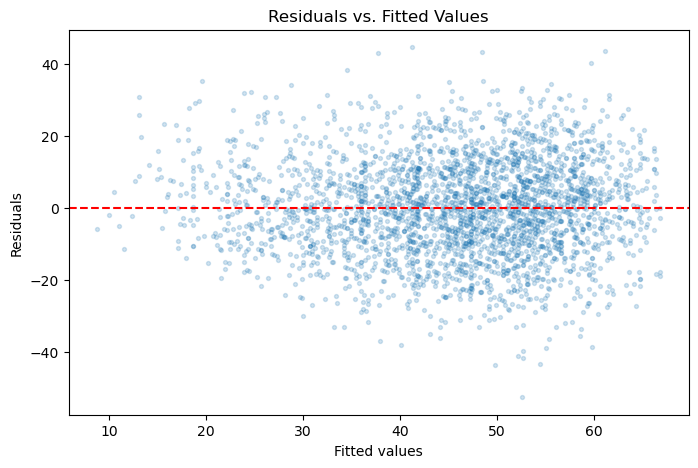

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(
    ols_phq9.fittedvalues,
    ols_phq9.resid,
    alpha=0.2,
    s=8
)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values")
plt.savefig("residuals_vs_fitted_values.png", dpi=300, bbox_inches="tight")
plt.show()

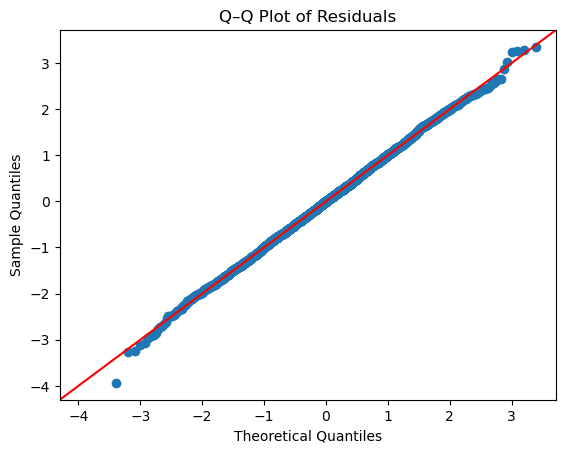

In [62]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

sm.qqplot(ols_phq9.resid, line="45", fit=True)
plt.title("Q–Q Plot of Residuals")
plt.savefig("q_q_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [63]:
cooks_d = influence.cooks_distance[0]

print("Observations with Cook's distance > 4/n:",
      (cooks_d > 4 / len(model_data_phq9)).sum())

print("Maximum Cook's distance:",
      round(cooks_d.max(), 4))

Observations with Cook's distance > 4/n: 143
Maximum Cook's distance: 0.0065


In [64]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X = ols_phq9.model.exog
names = ols_phq9.model.exog_names

vif = pd.DataFrame({
    "Variable": names,
    "VIF": [
        variance_inflation_factor(X, i)
        for i in range(X.shape[1])
    ]
})

print(vif.round(2).to_string(index=False))

                                 Variable    VIF
                                Intercept 117.93
                           C(sex)[T.Male]   1.03
C(education)[T.College graduate or above]   2.07
 C(education)[T.High school graduate/GED]   2.05
      C(education)[T.Less than 9th grade]   1.60
   C(education)[T.Some college/AA degree]   2.18
                 C(stroke_history)[T.Yes]   1.03
                                 RIDAGEYR   1.02
                               PHQ9_score   1.06


In [65]:
model_interaction_phq9 = sample_phq9.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cat("stroke_history", ref="No"),
        "PHQ9_score",
        svy.Cross(
            "RIDAGEYR",
            svy.Cat("education", ref="9th–11th grade")
        )
    ],
    family="gaussian"
)

print(model_interaction_phq9)

╭───────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                                    │
│                                                                                                                    │
│ Observations         2936  AIC           23407.6668                                                                │
│ DF Residuals           20  BIC                    -                                                                │
│ Deviance      492358.4430  Scale           168.4428                                                                │
│ R-squared         0.41103  R-sq (adj)       0.40861                                                                │
│                            Iterations             2                                                                │
│ F-stat (adj)     70.03115  Prob (F-adj)      <0.001                                                                │
│                                                                                                                    │
│                                                                                                                    │
│  Term                                               Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                     94.14620   10.19501     9.23454   <0.001    72.87978   115.41261  │
│  RIDAGEYR                                        -0.68855    0.14127    -4.87400   <0.001    -0.98324    -0.39387  │
│  sex_Male                                        -5.20189    0.46049   -11.29635   <0.001    -6.16247    -4.24132  │
│  education_College graduate or above             40.65355   11.82040     3.43927   0.0026    15.99663    65.31046  │
│  education_High school graduate/GED               9.19633   11.72178     0.78455   0.4419   -15.25487    33.64752  │
│  education_Less than 9th grade                  -24.33316   15.15250    -1.60588   0.1240   -55.94072     7.27439  │
│  education_Some college/AA degree                37.73039   11.18459     3.37343   0.0030    14.39975    61.06103  │
│  stroke_history_Yes                              -5.39927    1.05262    -5.12936   <0.001    -7.59499    -3.20354  │
│  PHQ9_score                                      -0.59536    0.09181    -6.48504   <0.001    -0.78686    -0.40386  │
│  RIDAGEYR:education_College graduate or above    -0.34757    0.16272    -2.13599   0.0452    -0.68701    -0.00814  │
│  RIDAGEYR:education_High school graduate/GED     -0.03474    0.16601    -0.20927   0.8364    -0.38103     0.31155  │
│  RIDAGEYR:education_Less than 9th grade           0.18086    0.20866     0.86678   0.3963    -0.25440     0.61613  │
│  RIDAGEYR:education_Some college/AA degree       -0.36798    0.15796    -2.32964   0.0304    -0.69747    -0.03849  │
│                                                                                                                    │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [66]:
print("Coefficients:")
print(fit.coefs)

print("\nCovariance matrix shape:")
print(fit.cov_matrix.shape)

print("\nDesign degrees of freedom:")
print(fit._design_df())

Coefficients:
[GLMCoef(term='_intercept_', est=np.float64(87.90443388781819), se=np.float64(9.399148961424677), lci=np.float64(68.41179199550156), uci=np.float64(107.39707578013481), wald=TDist(df=22, value=np.float64(9.352382247434246), p_value=np.float64(4.023451838413529e-09)), wald_adj=None, label=None), GLMCoef(term='RIDAGEYR', est=np.float64(-0.6457087741466252), se=np.float64(0.13007513435471527), lci=np.float64(-0.9154680920888654), uci=np.float64(-0.37594945620438497), wald=TDist(df=22, value=np.float64(-4.964121523686268), p_value=np.float64(5.746801159537123e-05)), wald_adj=None, label=None), GLMCoef(term='sex_Male', est=np.float64(-4.640305777594508), se=np.float64(0.501646018965971), lci=np.float64(-5.680655945949302), uci=np.float64(-3.5999556092397134), wald=TDist(df=22, value=np.float64(-9.250159678650377), p_value=np.float64(4.888624635793868e-09)), wald_adj=None, label=None), GLMCoef(term='education_College graduate or above', est=np.float64(47.91662035074998), se=np.

In [67]:
import numpy as np
from scipy import stats

# Identify the four age-by-education interaction terms
interaction_indices = [
    i for i, coef in enumerate(fit.coefs)
    if coef.term.startswith("RIDAGEYR:education_")
]

# Extract coefficients and their covariance matrix
beta = np.array([
    fit.coefs[i].est for i in interaction_indices
])

cov = np.asarray(fit.cov_matrix)[
    np.ix_(interaction_indices, interaction_indices)
]

# Joint Wald F-test
q = len(interaction_indices)
wald_chi2 = beta @ np.linalg.solve(cov, beta)
f_stat = wald_chi2 / q
df_den = fit._design_df()
p_value = stats.f.sf(f_stat, q, df_den)

print("Number of interaction terms:", q)
print("F-statistic:", round(f_stat, 3))
print("Degrees of freedom:", (q, int(df_den)))
print("Joint-test p-value:", f"{p_value:.6f}")

Number of interaction terms: 4
F-statistic: 9.114
Degrees of freedom: (4, 22)
Joint-test p-value: 0.000169


In [68]:
# Extract results from the primary survey-weighted model
results = []

for coef in model_phq9._ensure_fitted().coefs:
    results.append({
        "Variable": coef.term,
        "Coefficient": coef.est,
        "95% CI lower": coef.lci,
        "95% CI upper": coef.uci,
        "p-value": coef.wald.p_value
    })

# Create a DataFrame
results_df = pd.DataFrame(results)

# Format p-values: show very small values as <0.001
results_df["p-value"] = results_df["p-value"].apply(
    lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
)

# Round coefficients and confidence intervals
results_df[
    [
        "Variable",
        "Coefficient",
        "95% CI lower",
        "95% CI upper",
        "p-value"
    ]
].round(3)


,Variable,Coefficient,95% CI lower,95% CI upper,p-value
0,_intercept_,109.358,102.212,116.504,<0.001
1,RIDAGEYR,-0.904,-0.996,-0.811,<0.001
2,sex_Male,-5.293,-6.265,-4.320,<0.001
3,education_College graduate or above,16.462,14.180,18.744,<0.001
4,education_High school graduate/GED,6.640,5.023,8.257,<0.001
5,education_Less than 9th grade,-11.348,-14.155,-8.541,<0.001
6,education_Some college/AA degree,12.065,10.253,13.878,<0.001
7,stroke_history_Yes,-5.419,-7.666,-3.172,<0.001
8,PHQ9_score,-0.611,-0.807,-0.416,<0.001


In [69]:
results_interaction = []

for coef in model_interaction_phq9._ensure_fitted().coefs:
    results_interaction.append({
        "Variable": coef.term,
        "Coefficient": coef.est,
        "95% CI lower": coef.lci,
        "95% CI upper": coef.uci,
        "p-value": coef.wald.p_value
    })

results_interaction_df = pd.DataFrame(results_interaction)

results_interaction_df["p-value"] = results_interaction_df["p-value"].apply(
    lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
)

results_interaction_df[
    ["Variable", "Coefficient", "95% CI lower", "95% CI upper", "p-value"]
].round(3)

,Variable,Coefficient,95% CI lower,95% CI upper,p-value
0,_intercept_,94.146,72.880,115.413,<0.001
1,RIDAGEYR,-0.689,-0.983,-0.394,<0.001
2,sex_Male,-5.202,-6.162,-4.241,<0.001
3,education_College graduate or above,40.654,15.997,65.310,0.003
4,education_High school graduate/GED,9.196,-15.255,33.648,0.442
5,education_Less than 9th grade,-24.333,-55.941,7.274,0.124
6,education_Some college/AA degree,37.730,14.400,61.061,0.003
7,stroke_history_Yes,-5.399,-7.595,-3.204,<0.001
8,PHQ9_score,-0.595,-0.787,-0.404,<0.001
9,RIDAGEYR:education_College graduate or above,-0.348,-0.687,-0.008,0.045


In [70]:
labels = {
    "_intercept_": "Intercept",
    "RIDAGEYR": "Age (years)",
    "sex_Male": "Male",
    "education_College graduate or above": "College graduate or above",
    "education_High school graduate/GED": "High school graduate or GED",
    "education_Less than 9th grade": "Less than 9th grade",
    "education_Some college/AA degree": "Some college or associate degree",
    "stroke_history_Yes": "History of stroke (yes vs. no)",
    "PHQ9_score": "PHQ-9 depression symptom score",
    "RIDAGEYR:education_College graduate or above": "Age × college graduate or above",
    "RIDAGEYR:education_High school graduate/GED": "Age × high school graduate or GED",
    "RIDAGEYR:education_Less than 9th grade": "Age × less than 9th grade",
    "RIDAGEYR:education_Some college/AA degree": "Age × some college or associate degree"
}

results_df["Variable"] = results_df["Variable"].replace(labels)
results_interaction_df["Variable"] = results_interaction_df["Variable"].replace(labels)

In [71]:
model_data_phq9.groupby("stroke_history")["CFDDS"].agg(
    ["count", "mean", "std"]
).round(2)

,count,mean,std
stroke_history,,,
No,2730,46.40,17.21
Yes,206,36.28,16.76


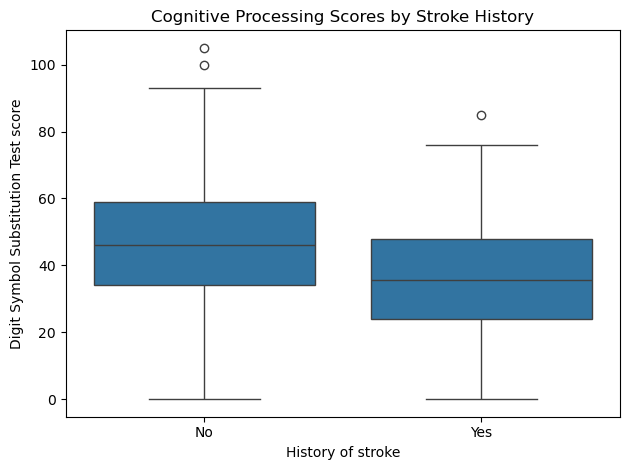

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=model_data_phq9, x="stroke_history", y="CFDDS")

plt.xlabel("History of stroke")
plt.ylabel("Digit Symbol Substitution Test score")
plt.title("Cognitive Processing Scores by Stroke History")
plt.tight_layout()
plt.savefig("stroke_history_score.png", dpi=300, bbox_inches="tight")
plt.show()

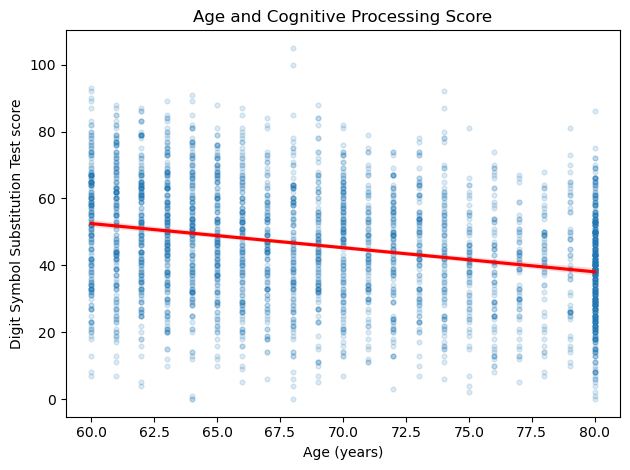

In [73]:
sns.regplot(
    data=model_data_phq9,
    x="RIDAGEYR",
    y="CFDDS",
    scatter_kws={"alpha": 0.15, "s": 12},
    line_kws={"color": "red"}
)

plt.xlabel("Age (years)")
plt.ylabel("Digit Symbol Substitution Test score")
plt.title("Age and Cognitive Processing Score")
plt.tight_layout()
plt.savefig("age_cognitive_score.png", dpi=300, bbox_inches="tight")
plt.show()

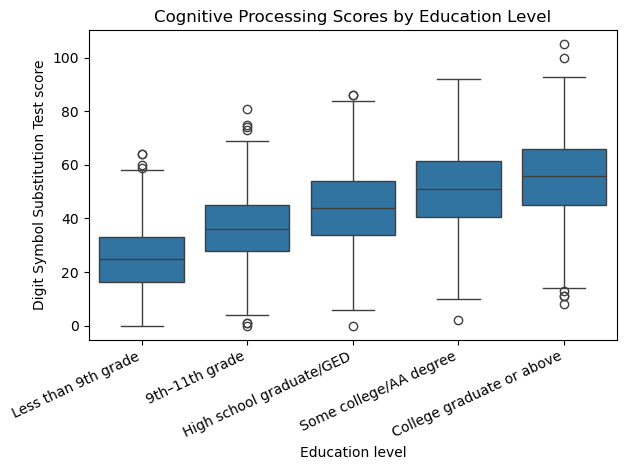

In [74]:
sns.boxplot(
    data=model_data_phq9,
    x="education",
    y="CFDDS",
    order=[
        "Less than 9th grade",
        "9th–11th grade",
        "High school graduate/GED",
        "Some college/AA degree",
        "College graduate or above"
    ]
)

plt.xlabel("Education level")
plt.ylabel("Digit Symbol Substitution Test score")
plt.title("Cognitive Processing Scores by Education Level")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("education_level_score.png", dpi=300, bbox_inches="tight")
plt.show()

In [75]:
excluded = analysis.loc[
    ~analysis.index.isin(model_data_phq9.index)
]

columns_to_check = [
    "CFDDS",
    "RIDAGEYR",
    "sex",
    "education",
    "stroke_history",
    "PHQ9_score",
    "WTMEC4YR",
    "SDMVSTRA",
    "SDMVPSU"
]

excluded[columns_to_check].isna().sum().sort_values(
    ascending=False
)

PHQ9_score        70
stroke_history     5
education          3
CFDDS              0
RIDAGEYR           0
sex                0
WTMEC4YR           0
SDMVSTRA           0
SDMVPSU            0
dtype: int64

In [76]:
print("Final sample size:", len(model_data_phq9))

print("\nPrimary model")
print("R²:", 0.406)
print("AIC:", 23422.74)

print("\nInteraction model")
print("R²:", 0.411)
print("AIC:", 23407.67)

Final sample size: 2936

Primary model
R²: 0.406
AIC: 23422.74

Interaction model
R²: 0.411
AIC: 23407.67


In [77]:
print(results_df["Variable"].tolist())
print(results_interaction_df["Variable"].tolist())

['Intercept', 'Age (years)', 'Male', 'College graduate or above', 'High school graduate or GED', 'Less than 9th grade', 'Some college or associate degree', 'History of stroke (yes vs. no)', 'PHQ-9 depression symptom score']
['Intercept', 'Age (years)', 'Male', 'College graduate or above', 'High school graduate or GED', 'Less than 9th grade', 'Some college or associate degree', 'History of stroke (yes vs. no)', 'PHQ-9 depression symptom score', 'Age × college graduate or above', 'Age × high school graduate or GED', 'Age × less than 9th grade', 'Age × some college or associate degree']
